# Network Intrusion Detection — model training (NSL-KDD)

**Task:** binary classification. Predict whether a network connection record is `normal` or an `attack`.

**Dataset:** NSL-KDD (Tavallaee et al., 2009, Canadian Institute for Cybersecurity, University of New Brunswick).
It is a cleaned version of KDD Cup 1999 with redundant records removed.
* `KDDTrain+`: **125,973 rows × 43 columns** (41 traffic features + `attack_type` label + `difficulty_level`)
* `KDDTest+`: 22,544 rows. This is the official held-out test set, and it contains attack types that never appear in training.

The records are synthetic, simulated military-network traffic with no personal data. That makes them safe to use as a public sample payload.

This notebook produces `backend/models/model_bundle.joblib` (Stage 4) and `data/sample_inputs.csv` (Stage 5) for the full-stack lab.

In [1]:
from pathlib import Path
import json, platform, urllib.request

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
MODELS = ROOT / "backend" / "models"
RANDOM_STATE = 42

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib      :", joblib.__version__)

Python      : 3.12.10
pandas      : 3.1.0
numpy       : 2.5.4
scikit-learn: 1.9.1
joblib      : 1.6.0


## 1. Load the dataset
If the CSVs are missing (they are not committed to Git), this cell downloads the raw files and adds the column header.

In [2]:
COLUMNS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "attack_type", "difficulty_level",
]
MIRROR = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"

def load_split(local_name, remote_name):
    path = DATA / local_name
    if not path.exists():
        print("Downloading", remote_name)
        DATA.mkdir(exist_ok=True)
        with urllib.request.urlopen(MIRROR + remote_name, timeout=120) as r:
            pd.read_csv(r, header=None, names=COLUMNS).to_csv(path, index=False)
    return pd.read_csv(path)

train_df = load_split("nsl_kdd_train.csv", "KDDTrain%2B.txt")
test_df = load_split("nsl_kdd_test.csv", "KDDTest%2B.txt")
print("Train:", train_df.shape, " Test:", test_df.shape)
train_df.head()

Train: (125973, 43)  Test: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 2. Exploratory checks

In [3]:
print("Missing values (train):", int(train_df.isna().sum().sum()))
print("Duplicate rows (train):", int(train_df.duplicated().sum()))
print("\nColumn types:")
print(train_df.dtypes.value_counts())
print("\nCategorical cardinality:")
print(train_df[["protocol_type", "service", "flag"]].nunique())
print("\nConstant columns:", [c for c in train_df.columns if train_df[c].nunique() == 1])

Missing values (train): 0


Duplicate rows (train): 0

Column types:
int64      24
float64    15
str         4
Name: count, dtype: int64

Categorical cardinality:
protocol_type     3
service          70
flag             11
dtype: int64

Constant columns: ['num_outbound_cmds']


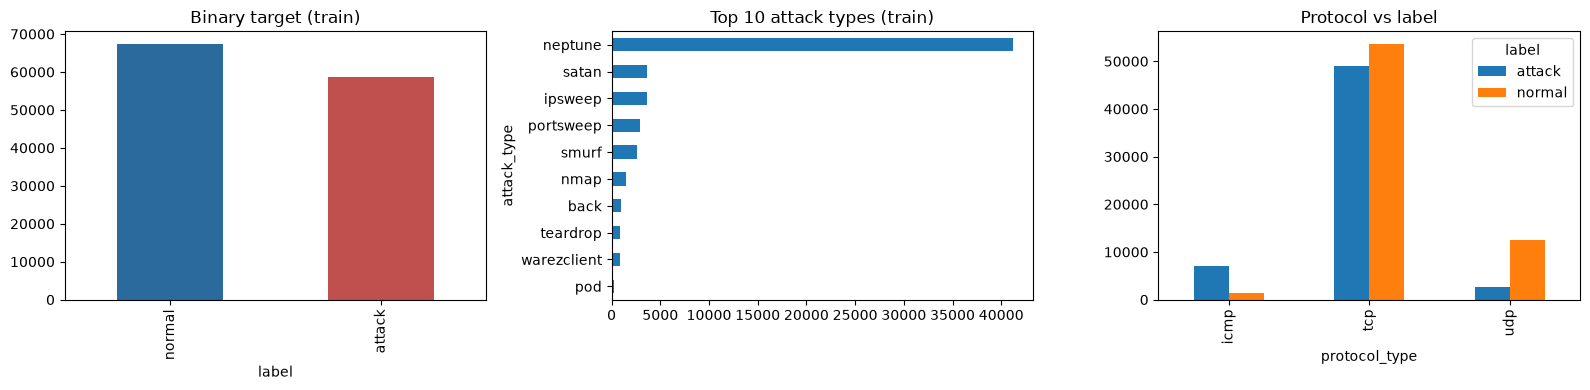

label
normal    0.535
attack    0.465
Name: proportion, dtype: float64

Attack types in KDDTest+ never seen in training (17): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [4]:
train_df["label"] = np.where(train_df["attack_type"] == "normal", "normal", "attack")
test_df["label"] = np.where(test_df["attack_type"] == "normal", "normal", "attack")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
train_df["label"].value_counts().plot.bar(ax=axes[0], color=["#2a6a9c", "#c0504d"])
axes[0].set_title("Binary target (train)")
train_df.loc[train_df.label == "attack", "attack_type"].value_counts().head(10).plot.barh(ax=axes[1])
axes[1].set_title("Top 10 attack types (train)")
axes[1].invert_yaxis()
pd.crosstab(train_df.protocol_type, train_df.label).plot.bar(ax=axes[2])
axes[2].set_title("Protocol vs label")
plt.tight_layout()
plt.show()

print(train_df["label"].value_counts(normalize=True).round(3))
unseen = sorted(set(test_df.attack_type) - set(train_df.attack_type))
print(f"\nAttack types in KDDTest+ never seen in training ({len(unseen)}):", unseen)

## 3. Feature schema

* **Target:** `label` (`attack` / `normal`), derived from `attack_type`. The target is never sent as a predictor.
* **Dropped:** `attack_type` (it is the target), `difficulty_level` (dataset-authoring metadata, not a traffic measurement, so it would leak information), `num_outbound_cmds` (always 0 in training).
* **Model inputs:** 40 raw features, 3 categorical and 37 numeric. The Flask API and the Angular form use exactly this list, in this order.

In [5]:
CATEGORICAL = ["protocol_type", "service", "flag"]
DROP = ["attack_type", "difficulty_level", "num_outbound_cmds", "label"]
FEATURES = [c for c in COLUMNS if c not in DROP]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

X = train_df[FEATURES]
y = train_df["label"]
X_test, y_test = test_df[FEATURES], test_df["label"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"{len(FEATURES)} features ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print("Train:", X_train.shape, " Validation:", X_val.shape, " Official test:", X_test.shape)

40 features (37 numeric, 3 categorical)
Train: (100778, 40)  Validation: (25195, 40)  Official test: (22544, 40)


## 4. Fitted preprocessing + model in one sklearn Pipeline

* Numeric: `log1p`, because bytes and durations are very heavily skewed and all values are ≥ 0, followed by `StandardScaler`.
* Categorical: `OneHotEncoder(handle_unknown="ignore")`, so an unseen service or flag cannot crash inference.
* Estimator: `LogisticRegression`.

The scaler and encoder are fitted **only on training rows** and saved together with the model. That way the API never refits preprocessing on a single record.

In [6]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
pipeline.fit(X_train, y_train)
print("Classes (probability order):", list(pipeline.classes_))

Classes (probability order): ['attack', 'normal']


## 5. Evaluation
The positive class is `attack`. KDDTest+ is deliberately harder than the validation split because it contains novel attack types.

In [7]:
def evaluate(name, X_, y_):
    pred = pipeline.predict(X_)
    proba = pipeline.predict_proba(X_)[:, list(pipeline.classes_).index("attack")]
    return {
        "split": name,
        "accuracy": round(accuracy_score(y_, pred), 4),
        "precision": round(precision_score(y_, pred, pos_label="attack"), 4),
        "recall": round(recall_score(y_, pred, pos_label="attack"), 4),
        "f1": round(f1_score(y_, pred, pos_label="attack"), 4),
        "roc_auc": round(roc_auc_score((y_ == "attack").astype(int), proba), 4),
    }

metrics = pd.DataFrame([evaluate("validation (20% of KDDTrain+)", X_val, y_val),
                        evaluate("official test (KDDTest+)", X_test, y_test)])
metrics

,split,accuracy,precision,recall,f1,roc_auc
0,validation (20% of KDDTrain+),0.9864,0.9864,0.9844,0.9854,0.9980
1,official test (KDDTest+),0.7447,0.9131,0.6095,0.7311,0.8006


              precision    recall  f1-score   support

      attack      0.913     0.610     0.731     12833
      normal      0.642     0.923     0.757      9711

    accuracy                          0.745     22544
   macro avg      0.777     0.766     0.744     22544
weighted avg      0.796     0.745     0.742     22544



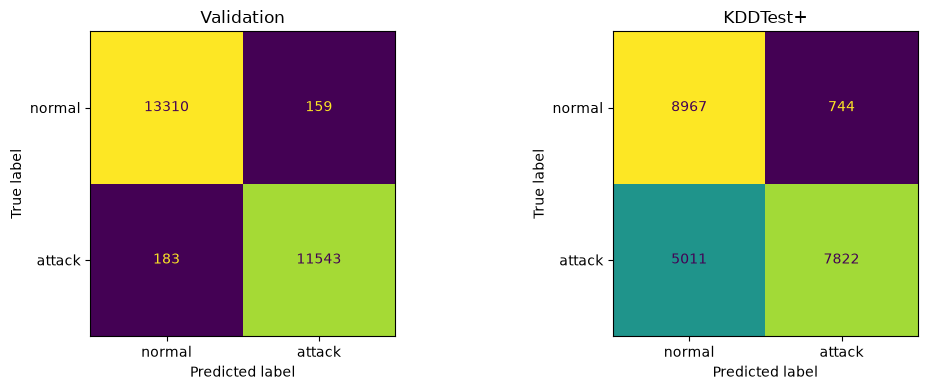

In [8]:
print(classification_report(y_test, pipeline.predict(X_test), digits=3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, X_, y_) in zip(axes, [("Validation", X_val, y_val), ("KDDTest+", X_test, y_test)]):
    ConfusionMatrixDisplay(confusion_matrix(y_, pipeline.predict(X_), labels=["normal", "attack"]),
                           display_labels=["normal", "attack"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

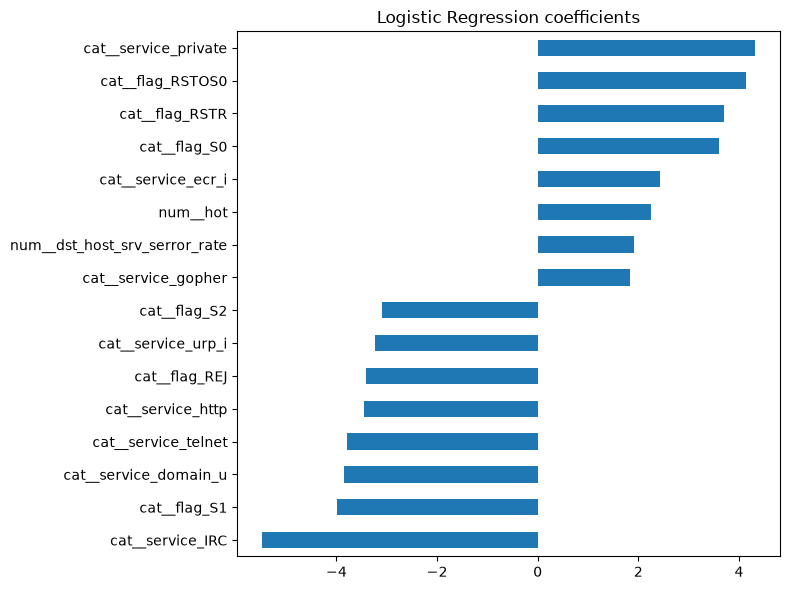

In [9]:
# Most influential one-hot / scaled inputs (positive = pushes towards "attack")
names = pipeline.named_steps["preprocess"].get_feature_names_out()
sign = 1 if pipeline.classes_[1] == "attack" else -1
coefs = pd.Series(sign * pipeline.named_steps["model"].coef_[0], index=names).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(8, 6), title="Logistic Regression coefficients")
plt.tight_layout()
plt.show()

## 6. Input schema, sample record and model bundle

The API and the Angular form use this schema:
* Categorical options are the exact labels the fitted encoder learned.
* Numeric ranges: every feature is ≥ 0. Rate features and 0/1 flags are capped at 1. Counts from the 2-second and 100-connection windows are capped at the dataset limits (511 and 255).

In [10]:
RATE_OR_FLAG = [c for c in NUMERIC if c.endswith("_rate") or c in
                ("land", "logged_in", "root_shell", "is_host_login", "is_guest_login")]
LIMITS = {"count": 511, "srv_count": 511, "dst_host_count": 255, "dst_host_srv_count": 255}

schema = []
for name in FEATURES:
    entry = {"name": name, "label": name.replace("_", " ").capitalize()}
    if name in CATEGORICAL:
        entry.update(kind="category", options=sorted(X_train[name].unique().tolist()))
    else:
        entry.update(kind="number", min=0)
        if name in RATE_OR_FLAG:
            entry["max"] = 1
        elif name in LIMITS:
            entry["max"] = LIMITS[name]
    schema.append(entry)

# One non-sensitive validation record (an attack, so the demo shows a non-trivial result)
sample = X_val[y_val == "attack"].head(1)
sample.to_csv(DATA / "sample_inputs.csv", index=False)
expected = {"prediction": pipeline.predict(sample)[0],
            "probabilities": pipeline.predict_proba(sample)[0].round(6).tolist()}
print("Sample record true label :", y_val[sample.index[0]])
print("Expected model output    :", expected)
sample.T.head(12)

Sample record true label : attack
Expected model output    : {'prediction': 'attack', 'probabilities': [0.986881, 0.013119]}


,86055
duration,0
protocol_type,icmp
service,ecr_i
flag,SF
src_bytes,1032
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


In [11]:
bundle = {
    "pipeline": pipeline,
    "features": FEATURES,
    "task": "classification",
    "model_version": "1.0",
    # extra metadata used by the API for validation and by the frontend schema export
    "classes": [str(c) for c in pipeline.classes_],
    "positive_class": "attack",
    "schema": schema,
    "metrics": metrics.to_dict(orient="records"),
    "trained_with": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                     "pandas": pd.__version__, "numpy": np.__version__},
    "dataset": "NSL-KDD (KDDTrain+ 125,973 rows x 43 columns)",
}
MODELS.mkdir(parents=True, exist_ok=True)
joblib.dump(bundle, MODELS / "model_bundle.joblib", compress=3)
(ROOT / "docs" / "expected_sample_output.json").write_text(json.dumps(expected, indent=2))
print("Saved:", MODELS / "model_bundle.joblib",
      f"({(MODELS / 'model_bundle.joblib').stat().st_size / 1024:.1f} KB)")

Saved: C:\Users\USER\OneDrive\문서\DevOps-LABtask\backend\models\model_bundle.joblib (5.3 KB)


In [12]:
# Stage 4.5 check: the bundle reloads and predicts
b = joblib.load(MODELS / "model_bundle.joblib")
print(b.keys())
print(len(b["features"]), "features:", b["features"][:5], "...")
print(type(b["pipeline"]))
assert b["pipeline"].predict(sample)[0] == expected["prediction"]
print("PASS: bundle reload")

dict_keys(['pipeline', 'features', 'task', 'model_version', 'classes', 'positive_class', 'schema', 'metrics', 'trained_with', 'dataset'])
40 features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes'] ...
<class 'sklearn.pipeline.Pipeline'>
PASS: bundle reload
